In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
df = pd.read_csv("Ask A Manager Salary Survey 2024 (Responses) - Form Responses 1.csv")
df.head()


,Timestamp,How old are you?,What industry is your employer in?,What is the functional area of your job (this might be different from your company's industry)?,Job title,"If your job title needs additional context, please clarify here:","What is your annual salary? This should be your GROSS (pre-tax) income. (You'll indicate the currency in a later question.) If you are part-time or hourly, please enter an annualized equivalent -- what you would earn if you worked the job 40 hours a week, 52 weeks a year.","How much additional monetary compensation do you get, if any (for example, bonuses or overtime in an average year)? Only include monetary compensation here, not the value of benefits, tuition reimbursement, etc. If your bonus or overtime varies from year to year, use the most recent figures.",Please indicate the currency,"If ""Other,"" please indicate the currency here:",...,What country do you work in? (Countries listed had by far the largest representation last year. Please write in your country if it's not listed.),"If you're in the U.S., what state do you work in?",What city/region do you work in?,Are you remote or on-site?,Is your job unionized?,How many years of professional work experience do you have overall?,How many years of professional work experience do you have in your field?,What is your highest level of education completed?,What is your gender?,What is your race? (Choose all that apply.)
0,4/9/2024 11:01:42,25-34,Media & Digital,Media & Digital,Digital Project Manager,NaN,73000,NaN,USD,NaN,...,United States,New York,New York,Hybrid,No,5-7 years,5-7 years,College degree,Woman,White
1,4/9/2024 11:02:14,35-44,Education (Higher Education),Health care,Senior Director,NaN,150000,4500.0,USD,NaN,...,United States,California,Norhtern,Hybrid,No,11-20 years,11-20 years,College degree,Woman,White
2,4/9/2024 11:02:18,35-44,Nonprofits,Administration,Advancement Operations Manager,NaN,53800,NaN,USD,NaN,...,United States,Maryland,Olney,Hybrid,No,11-20 years,8-10 years,Master's degree,Woman,White
3,4/9/2024 11:02:19,25-34,Government & Public Administration,Government & Public Administration,Program Analyst,NaN,97000,0.0,USD,NaN,...,United States,Colorado,Fort Collins,Fully remote,No,8-10 years,8-10 years,Master's degree,Woman,White
4,4/9/2024 11:02:24,25-34,Government & Public Administration,Administration,Project Coordinator,NaN,64000,NaN,USD,NaN,...,United States,Massachusetts,Boston,Hybrid,No,8-10 years,2-4 years,College degree,Woman,White


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("Ask A Manager Salary Survey 2024 (Responses) - Form Responses 1.csv")

df.columns = (
    df.columns
    .str.replace("\s+", " ", regex=True)
    .str.strip()
)

def find_like(substr):
    hits = [c for c in df.columns if substr.lower() in c.lower()]
    return hits[0] if hits else None

age_col     = find_like("How old are you")
ind_col     = find_like("industry is your employer")
title_col   = find_like("job title")
salary_col  = find_like("annual salary")
country_col = find_like("what country do you work in")
currency_col = find_like("Please indicate the currency")   # <-- NEW

mapping = {
    age_col: "age",
    ind_col: "industry",
    title_col: "job_title",
    salary_col: "annual_salary",
    country_col: "country",
    currency_col: "currency"   # <-- NEW
}

df = df.rename(columns=mapping)

keep = ["age", "industry", "job_title", "annual_salary", "country", "currency"]
df = df[keep].copy()

df.head()


,age,industry,job_title,annual_salary,country,currency
0,25-34,Media & Digital,Digital Project Manager,73000,United States,USD
1,35-44,Education (Higher Education),Senior Director,150000,United States,USD
2,35-44,Nonprofits,Advancement Operations Manager,53800,United States,USD
3,25-34,Government & Public Administration,Program Analyst,97000,United States,USD
4,25-34,Government & Public Administration,Project Coordinator,64000,United States,USD


In [4]:
rates_to_usd = {
    "USD": 1.00,
    "EUR": 1 / 0.86,
    "GBP": 1 / 0.79,
    "CAD": 1 / 0.59,
    "AUD": 1 / 0.52,
    "INR": 1 / 0.0095,
    "JPY": 1 / 0.0052,
    "NZD": 1 / 0.47,
    "CHF": 1 / 0.90
}

df["currency"] = df["currency"].astype(str).str.upper().str[:3]

df["Salary_in_USD"] = df.apply(
    lambda row: row["annual_salary"] * rates_to_usd.get(row["currency"], np.nan),
    axis=1
)

df = df.dropna(subset=["Salary_in_USD"])

df.head()


,age,industry,job_title,annual_salary,country,currency,Salary_in_USD
0,25-34,Media & Digital,Digital Project Manager,73000,United States,USD,73000.0
1,35-44,Education (Higher Education),Senior Director,150000,United States,USD,150000.0
2,35-44,Nonprofits,Advancement Operations Manager,53800,United States,USD,53800.0
3,25-34,Government & Public Administration,Program Analyst,97000,United States,USD,97000.0
4,25-34,Government & Public Administration,Project Coordinator,64000,United States,USD,64000.0


In [5]:
df['Salary_in_USD'] = pd.to_numeric(df['Salary_in_USD'], errors='coerce')

df = df.dropna(subset=['Salary_in_USD'])

df = df[(df['Salary_in_USD'] >= 5000) & (df['Salary_in_USD'] <= 1_000_000)].copy()

df.shape


(13261, 7)

In [6]:
def income_tier(s):
    if s <= 70000:
        return "Low"
    elif s <= 120000:
        return "Medium"
    else:
        return "High"

df['income_tier'] = df['Salary_in_USD'].apply(income_tier)

print(df['income_tier'].value_counts())


income_tier
Medium    5168
High      4172
Low       3921
Name: count, dtype: int64


In [7]:
def income_tier(s):
    if s <= 70_000:
        return "Low"
    elif s <= 100_000:
        return "Medium"
    else:
        return "High"

counts = df['income_tier'].value_counts()
print(counts.to_dict())



{'Medium': 5168, 'High': 4172, 'Low': 3921}


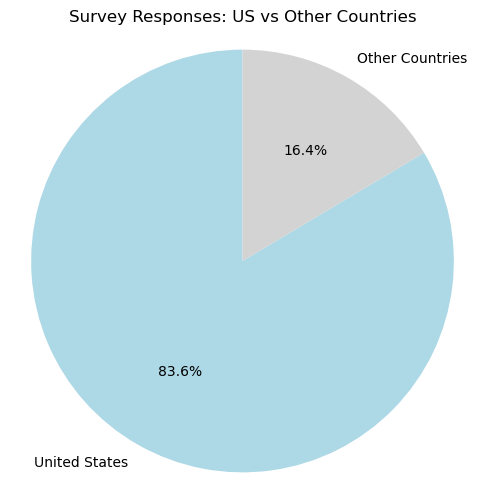

In [8]:
import matplotlib.pyplot as plt

us_count = df['country'].str.strip().str.lower().eq('united states').sum()
non_us_count = len(df) - us_count

labels = ['United States', 'Other Countries']
sizes = [us_count, non_us_count]
colors = ['lightblue', 'lightgray']

plt.figure(figsize=(6,6))
plt.pie(sizes, labels=labels, colors=colors, autopct='%1.1f%%', startangle=90)
plt.title('Survey Responses: US vs Other Countries')
plt.axis('equal')  # Equal aspect ratio ensures the pie chart is circular.
plt.show()


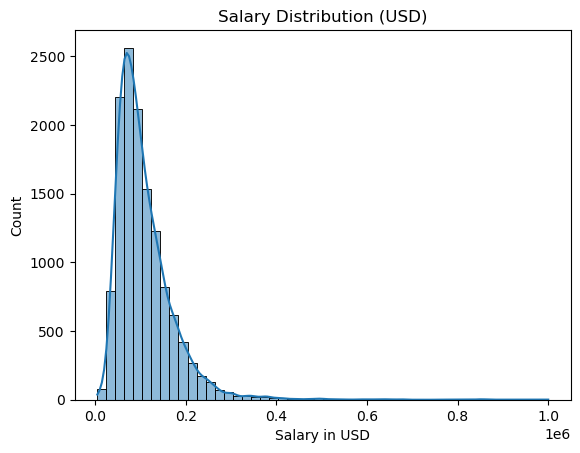

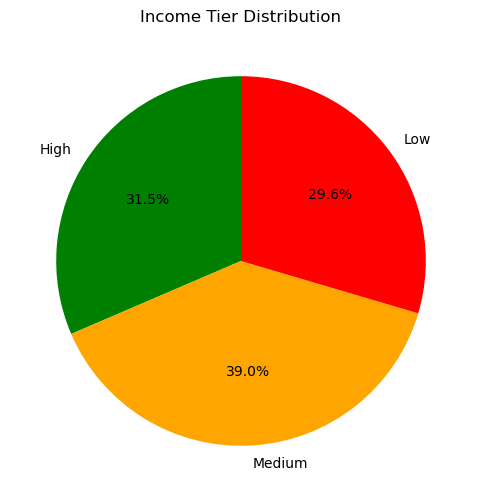

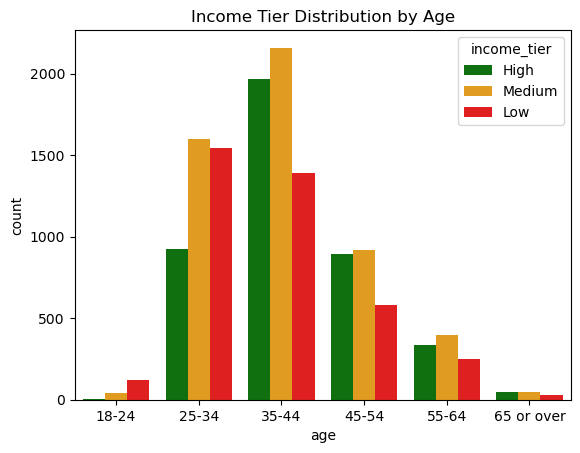

In [9]:
sns.histplot(df['Salary_in_USD'], bins=50, kde=True)
plt.title('Salary Distribution (USD)')
plt.xlabel('Salary in USD')
plt.show()

income_counts = df['income_tier'].value_counts()

income_counts = income_counts.reindex(['High', 'Medium', 'Low'])

plt.figure(figsize=(6,6))
plt.pie(
    income_counts,
    labels=income_counts.index,
    autopct='%1.1f%%',
    startangle=90,
    colors=['green', 'orange', 'red']  
)
plt.title('Income Tier Distribution')
plt.show()

sns.countplot(
    x='age',
    hue='income_tier',
    hue_order=['High', 'Medium', 'Low'],   
    palette=['green', 'orange', 'red'],    
    data=df,
    order=sorted(df['age'].unique())       
)
plt.title('Income Tier Distribution by Age')
plt.show()




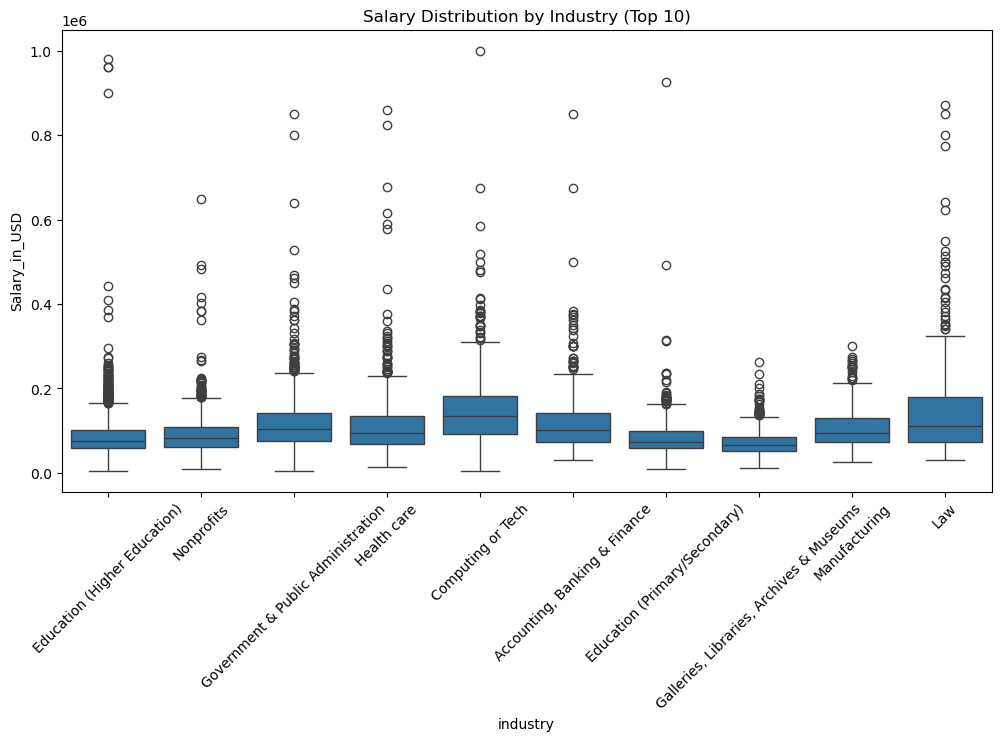

In [10]:
top_industries = df['industry'].value_counts().head(10).index

plt.figure(figsize=(12,6))
sns.boxplot(
    data=df[df['industry'].isin(top_industries)],
    x='industry',
    y='Salary_in_USD'
)
plt.xticks(rotation=45)
plt.title('Salary Distribution by Industry (Top 10)')
plt.show()


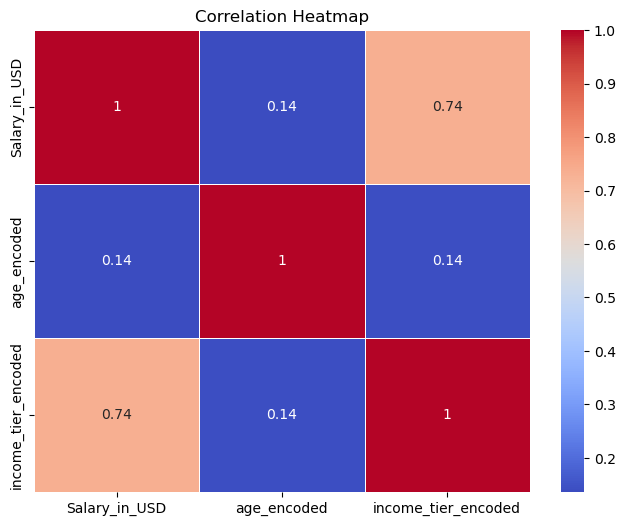

In [11]:
age_map = {
    '18-24': 1, '25-34': 2, '35-44': 3,
    '45-54': 4, '55-64': 5, '65+': 6
}
df['age_encoded'] = df['age'].map(age_map)

tier_map = {'Low': 1, 'Medium': 2, 'High': 3}
df['income_tier_encoded'] = df['income_tier'].map(tier_map)

plt.figure(figsize=(8,6))
sns.heatmap(
    df[['Salary_in_USD', 'age_encoded', 'income_tier_encoded']].corr(),
    annot=True,
    cmap='coolwarm',
    linewidths=.5
)
plt.title('Correlation Heatmap')
plt.show()

In [12]:
df.groupby('country')['Salary_in_USD'] \
  .mean() \
  .sort_values(ascending=False) \
  .head(10) \
  .round(2) \
  .reset_index()


,country,Salary_in_USD
0,New Zealand,361702.13
1,New Zealand,266805.00
2,New Zealand,248011.35
3,NZ,231560.28
4,Australia,230826.47
5,Hong Kong,230000.00
6,Aotearoa New Zealand,201653.19
7,Uzbekistan,180000.00
8,Canada,163043.73
9,Aotearoa New Zealand,161702.13


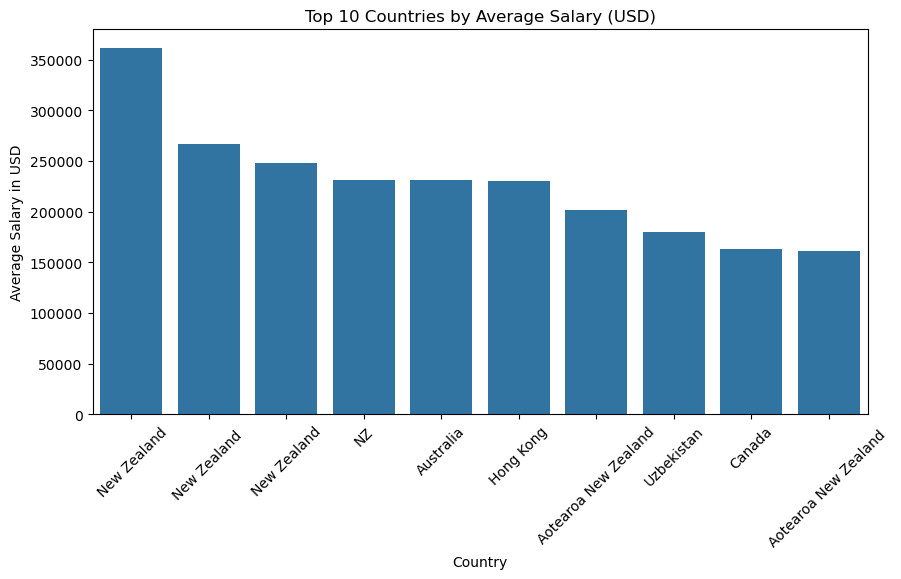

In [13]:
top_countries = df.groupby('country')['Salary_in_USD'].mean().sort_values(ascending=False).head(10)

plt.figure(figsize=(10,5))
sns.barplot(x=top_countries.index, y=top_countries.values)
plt.xticks(rotation=45)
plt.title('Top 10 Countries by Average Salary (USD)')
plt.ylabel('Average Salary in USD')
plt.xlabel('Country')
plt.show()


In [14]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

age_map = {
    '18-24': 1,
    '25-34': 2,
    '35-44': 3,
    '45-54': 4,
    '55-64': 5,
    '65+': 6
}
df['age_encoded'] = df['age'].map(age_map)

cluster_df = df[['age_encoded', 'Salary_in_USD', 'country']].dropna()

X_cluster = pd.get_dummies(cluster_df, drop_first=True)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_cluster)

kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
cluster_df['cluster'] = kmeans.fit_predict(X_scaled)

df = df.merge(cluster_df[['cluster']], left_index=True, right_index=True, how='left')

df.head()


,age,industry,job_title,annual_salary,country,currency,Salary_in_USD,income_tier,age_encoded,income_tier_encoded,cluster
0,25-34,Media & Digital,Digital Project Manager,73000,United States,USD,73000.0,Medium,2.0,2,0.0
1,35-44,Education (Higher Education),Senior Director,150000,United States,USD,150000.0,High,3.0,3,0.0
2,35-44,Nonprofits,Advancement Operations Manager,53800,United States,USD,53800.0,Low,3.0,1,0.0
3,25-34,Government & Public Administration,Program Analyst,97000,United States,USD,97000.0,Medium,2.0,2,0.0
4,25-34,Government & Public Administration,Project Coordinator,64000,United States,USD,64000.0,Low,2.0,1,0.0


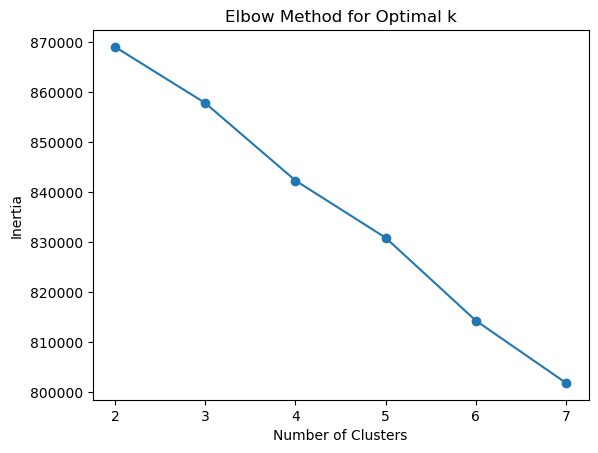

In [15]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

inertia = []
for k in range(2, 8):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

plt.plot(range(2, 8), inertia, marker='o')
plt.title('Elbow Method for Optimal k')
plt.xlabel('Number of Clusters')
plt.ylabel('Inertia')
plt.show()


In [16]:
for cluster, count in df['cluster'].value_counts().items():
    print(f"Cluster {cluster}: {count}")


Cluster 0.0: 11066
Cluster 1.0: 2072


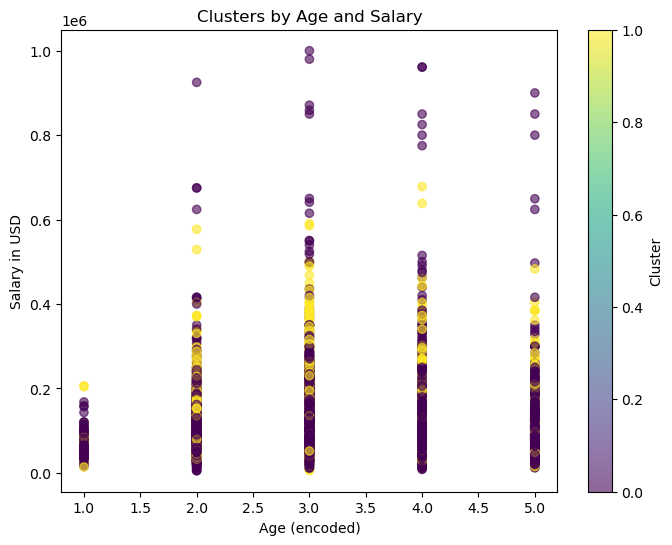

In [17]:
plt.figure(figsize=(8,6))
plt.scatter(
    cluster_df['age_encoded'],
    cluster_df['Salary_in_USD'],
    c=cluster_df['cluster'],
    cmap='viridis',
    alpha=0.6
)
plt.xlabel('Age (encoded)')
plt.ylabel('Salary in USD')
plt.title('Clusters by Age and Salary')
plt.colorbar(label='Cluster')
plt.show()


In [18]:
cluster_summary = cluster_df.groupby('cluster').agg(
    mean_salary = ('Salary_in_USD', 'mean'),
    min_salary  = ('Salary_in_USD', 'min'),
    max_salary  = ('Salary_in_USD', 'max'),
    mean_age    = ('age_encoded', 'mean')
).round(2)

cluster_summary


,mean_salary,min_salary,max_salary,mean_age
cluster,,,,
0,104226.27,5000.00,1000000.0,3.01
1,133484.60,5302.33,677966.1,2.93


In [19]:
df['income_tier'].value_counts()


income_tier
Medium    5168
High      4172
Low       3921
Name: count, dtype: int64

In [20]:
import numpy as np
import pandas as pd


def income_tier(s):
    if s <= 70_000:
        return "Low"
    elif s <= 100_000:
        return "Medium"
    else:
        return "High"

df['income_tier'] = df['Salary_in_USD'].apply(income_tier)

age_map = {
    '18-24': 1,
    '25-34': 2,
    '35-44': 3,
    '45-54': 4,
    '55-64': 5,
    '65+':   6
}

df['age_encoded'] = df['age'].map(age_map)


feature_cols = ['age_encoded', 'industry', 'job_title', 'country']

X_full = df[feature_cols].copy()
y_full = df['income_tier'].copy()

X_full_encoded = pd.get_dummies(X_full, drop_first=True)

print("Full encoded shapes:", X_full_encoded.shape, y_full.shape)


Full encoded shapes: (13261, 8844) (13261,)


In [21]:
train_n = 2000
rng = np.random.RandomState(42)

train_idx = []
test_idx = []

for tier in y_full.unique():
    tier_indices = y_full[y_full == tier].index

    n_available = len(tier_indices)
    n_train_tier = min(train_n, n_available)

    train_tier_idx = rng.choice(tier_indices, size=n_train_tier, replace=False)
    test_tier_idx = np.setdiff1d(tier_indices, train_tier_idx)

    train_idx.extend(train_tier_idx)
    test_idx.extend(test_tier_idx)

X_train = X_full_encoded.loc[train_idx]
y_train = y_full.loc[train_idx]

X_test = X_full_encoded.loc[test_idx]
y_test = y_full.loc[test_idx]

print("Train size:", X_train.shape)
print(y_train.value_counts())
print("\nTest size:", X_test.shape)
print(y_test.value_counts())


Train size: (6000, 8844)
income_tier
Medium    2000
High      2000
Low       2000
Name: count, dtype: int64

Test size: (7261, 8844)
income_tier
High      3865
Low       1921
Medium    1475
Name: count, dtype: int64


In [22]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

clf1 = DecisionTreeClassifier(random_state=42, max_depth=10)
clf1.fit(X_train, y_train)

y_pred = clf1.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nConfusion matrix:\n", confusion_matrix(y_test, y_pred))
print("\nClassification report:\n", classification_report(y_test, y_pred))


Accuracy: 0.5562594683927834

Confusion matrix:
 [[2914  187  764]
 [ 673  621  627]
 [ 729  242  504]]

Classification report:
               precision    recall  f1-score   support

        High       0.68      0.75      0.71      3865
         Low       0.59      0.32      0.42      1921
      Medium       0.27      0.34      0.30      1475

    accuracy                           0.56      7261
   macro avg       0.51      0.47      0.48      7261
weighted avg       0.57      0.56      0.55      7261



In [23]:
import joblib
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_auc_score
import numpy as np
import matplotlib.pyplot as plt

loaded = joblib.load("model1_income_tier.joblib")
clf = loaded["clf"]
columns = loaded["columns"]
age_map = loaded["age_map"]

classes = ['Low', 'Medium', 'High']

X_test_aligned = X_test.reindex(columns=columns, fill_value=0)

y_proba = clf.predict_proba(X_test_aligned)

y_test_bin = label_binarize(y_test, classes=classes)

class_counts = y_test.value_counts()
valid_classes = [c for c in classes if c in class_counts.index and class_counts[c] > 0]

valid_indices = [classes.index(c) for c in valid_classes]
y_test_bin_valid = y_test_bin[:, valid_indices]
y_proba_valid = y_proba[:, valid_indices]

macro_auc = roc_auc_score(
    y_test_bin_valid,
    y_proba_valid,
    multi_class='ovr',
    average='macro'
)

weighted_auc = roc_auc_score(
    y_test_bin_valid,
    y_proba_valid,
    multi_class='ovr',
    average='weighted'
)

print("Valid classes for AUC:", valid_classes)
print(f"Macro ROC AUC (OVR): {macro_auc:.4f}")
print(f"Weighted ROC AUC (OVR): {weighted_auc:.4f}")


Valid classes for AUC: ['Low', 'Medium', 'High']
Macro ROC AUC (OVR): 0.4240
Weighted ROC AUC (OVR): 0.4089


In [24]:
import joblib

model1 = {
    "clf": clf1,
    "columns": X_train.columns.tolist(),
    "age_map": age_map
}

joblib.dump(model1, "model1_income_tier.joblib")
print("Model 1 saved as 'model1_income_tier.joblib'")


Model 1 saved as 'model1_income_tier.joblib'


In [25]:
def predict_income_tier_model1(model, age, industry, job_title, country):
    """
    Predict income tier (Low / Medium / High) using saved Model 1.
    """

    clf = model["clf"]
    columns = model["columns"]
    age_map = model["age_map"]

    if isinstance(age, (int, float)):
        a = int(age)
        if a <= 24:
            age_band = '18-24'
        elif a <= 34:
            age_band = '25-34'
        elif a <= 44:
            age_band = '35-44'
        elif a <= 54:
            age_band = '45-54'
        elif a <= 64:
            age_band = '55-64'
        else:
            age_band = '65+'
    else:
        age_band = age

    age_encoded = age_map[age_band]

    row = pd.DataFrame({
        'age_encoded': [age_encoded],
        'industry': [industry],
        'job_title': [job_title],
        'country': [country],
    })

    X_new = pd.get_dummies(row, drop_first=True)
    X_new = X_new.reindex(columns=columns, fill_value=0)

    return clf.predict(X_new)[0]


In [26]:
model1 = joblib.load("model1_income_tier.joblib")

print(
    predict_income_tier_model1(
        model1,
        age=30,
        industry="Software",
        job_title="Software Engineer",
        country="United States"
    )
)

print(
    predict_income_tier_model1(
        model1,
        age=14,
        industry="Software",
        job_title="Software Engineer",
        country="United Kingdom"
    )
)

print(
    predict_income_tier_model1(
        model1,
        age=54,
        industry="Finance",
        job_title="Senior Analyst",
        country="Egypt"
    )
)


Low
Low
High


In [27]:
#Model 2

In [28]:
import pandas as pd

features = ['age_encoded', 'industry', 'job_title', 'country']
target = 'Salary_in_USD'

model2_df = df[features + [target]].dropna()

X = pd.get_dummies(model2_df[features], drop_first=True)
y = model2_df[target]


In [29]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)


In [30]:
from sklearn.ensemble import RandomForestRegressor

reg = RandomForestRegressor(
    n_estimators=200,
    random_state=42
)

print("Training Model 2 (Salary Predictor)... please wait.")

reg.fit(X_train, y_train)

print("✔ Training complete! Model 2 is now ready.")


Training Model 2 (Salary Predictor)... please wait.
✔ Training complete! Model 2 is now ready.


In [31]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

y_pred = reg.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R² Score:", r2)


MAE: 34917.33767137218
MSE: 3275307092.3878818
RMSE: 57230.298727054374
R² Score: 0.20835523862498617


In [32]:
import joblib

model2 = {
    "regressor": reg,
    "columns": X.columns.tolist()
}

joblib.dump(model2, "model2_salary_predictor.joblib")


['model2_salary_predictor.joblib']

In [33]:
def predict_salary(model_dict, age, industry, job_title, country):

    reg = model_dict["regressor"]
    columns = model_dict["columns"]

    # age band mapping
    if isinstance(age, int):
        if age <= 24: band = '18-24'
        elif age <= 34: band = '25-34'
        elif age <= 44: band = '35-44'
        elif age <= 54: band = '45-54'
        elif age <= 64: band = '55-64'
        else: band = '65+'
    else:
        band = age  

    age_encoded = age_map[band]

    row = pd.DataFrame({
        "age_encoded": [age_encoded],
        "industry": [industry],
        "job_title": [job_title],
        "country": [country]
    })

    row_encoded = pd.get_dummies(row, drop_first=True)
    row_encoded = row_encoded.reindex(columns=columns, fill_value=0)

    return reg.predict(row_encoded)[0]


In [34]:
import joblib

model2_dict = joblib.load("model2_salary_predictor.joblib")
print("Model 2 loaded successfully!")


Model 2 loaded successfully!


In [35]:
print(
    predict_salary(
        model2_dict,
        age=25,
        industry="Accounting, Banking & Finance",
        job_title="Assistant Finance Analyst",
        country="United Kingdom"
    )
)


49108.406037680295


In [36]:
print(
    predict_salary(
        model2_dict,
        age="45-54",
        industry="Nonprofits",
        job_title="Development Officer",
        country="United States"
    )
)

print(
    predict_salary(
        model2_dict,
        age="25-34",
        industry="Education (Primary/Secondary)",
        job_title="Teacher",
        country="United States"
    )
)

print(
    predict_salary(
        model2_dict,
        age="35-44",
        industry="Nonprofits",
        job_title="Graphic Designer",
        country="United States"
    )
)

print(
    predict_salary(
        model2_dict,
        age="35-44",
        industry="Media & Digital",
        job_title="Channel lineup associate",
        country="United States"
    )
)

print(
    predict_salary(
        model2_dict,
        age="45-54",
        industry="Engineering",
        job_title="Audiovisual Design Associate",
        country="United States"
    )
)

print(
    predict_salary(
        model2_dict,
        age="45-54",
        industry="Nonprofits",
        job_title="Archivist",
        country="United States"
    )
)

print(
    predict_salary(
        model2_dict,
        age="25-34",
        industry="Retail",
        job_title="Customer Support Agent",
        country="Canada"
    )
)

print(
    predict_salary(
        model2_dict,
        age="35-44",
        industry="Education (Higher Education)",
        job_title="Business Manager",
        country="United States"
    )
)
print(
    predict_salary(
        model2_dict,
        age="35-44",
        industry="Accounting, Banking & Finance",
        job_title="Accountant",
        country="United States"
    )
)


66511.1066187486
49108.406037680295
60686.411966441
60686.411966441
66511.1066187486
66511.1066187486
49108.406037680295
60686.411966441
60686.411966441


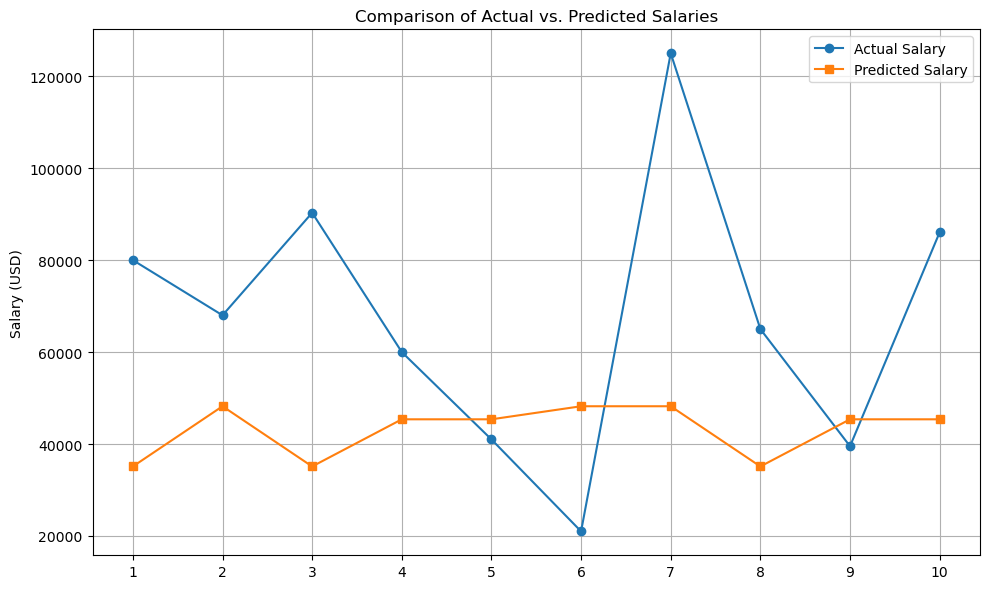

In [1]:
import matplotlib.pyplot as plt

actual = [80000, 68000, 90300, 60000, 41000, 21000, 125000, 65000, 39520, 86053]
predicted = [35120, 48215, 35120, 45375, 45375, 48215, 48215, 35120, 45375, 45375]

x = list(range(1, len(actual) + 1))

plt.figure(figsize=(10, 6))
plt.plot(x, actual, marker='o', label='Actual Salary')
plt.plot(x, predicted, marker='s', label='Predicted Salary')
plt.title('Comparison of Actual vs. Predicted Salaries')
plt.ylabel('Salary (USD)')
plt.xticks(x)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [38]:
import numpy as np
from sklearn.metrics import mean_squared_error, mean_absolute_error

actual = np.array([80000, 68000, 90300, 60000, 41000, 21000, 125000, 65000, 39520, 86053])
predicted = np.array([35120, 48215, 35120, 45375, 45375, 48215, 48215, 35120, 45375, 45375])

# Mean Absolute Error
mae = mean_absolute_error(actual, predicted)

# Mean Squared Error
mse = mean_squared_error(actual, predicted)

# Root Mean Squared Error
rmse = np.sqrt(mse)

print(f"MAE: {mae:.2f}")
print(f"MSE: {mse:.2f}")
print(f"RMSE: {rmse:.2f}")


MAE: 31925.80
MSE: 1490191183.40
RMSE: 38602.99


In [39]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

y_pred = reg.predict(X_test)

r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print("Model 2 Evaluation Metrics:")
print(f" R² score:            {r2:.4f}")
print(f" Mean Absolute Error: £{mae:,.2f}")
print(f" Root MSE:            £{rmse:,.2f}")


Model 2 Evaluation Metrics:
 R² score:            0.2084
 Mean Absolute Error: £34,917.34
 Root MSE:            £57,230.30
